# Лабораторная работа №8. Генерация и интерполяция в латентном пространстве

Власюк Данил Витальевич, Т26ИИКТ-МИК11. Вариант 3: VAE d=8 → d=2 на наборе «диск».

Цель: сравнить реконструкцию, интерполяцию, близость сэмплов и линейную связь латентного представления с факторами сцены. Работа выполняется в Engee на CPU по приложенной методичке. Скрипты lab07_lib.py, lab08_lib.py и lab08_demo.py сохранены без изменения. run_lr08.py - служебная проверка всех шести вариантов набора, в индивидуальном задании вместо неё вызывается V.variant_summary(3).

Данные синтетические, внешние веса и фотографии не используются. Подготовленная папка /user/AI_in_creative_media/LR08 содержит исходники, собственный исполняемый сценарий lr08_execute.py и гипотезу. Сначала выполните подготовку, затем полный эксперимент. Длительная ячейка обучает все модели и пишет живой журнал run.log. По окончании следующие ячейки покажут таблицы и изображения. Другие лабораторные не изменяются.

# Гипотеза и допуски до обучения ЛР8

Вариант 3, набор disc: янтарный диск на градиентном фоне, факторы x, y и радиус. A: VAE d=8; B: VAE d=2. Единственный изменяемый параметр - размер латентного вектора. beta=1, warmup=10 эпох, всего 30 эпох, Adam lr=0.002, batch=128, float32, линейная интерполяция, tau=1. Данные: 4096 train и 1024 test, data seed7. Seed обучения101–105. Вычисления на CPU в Engee, 4 потока (не более доступных), как в библиотеке.

Гипотеза: слишком узкое представление d=2 ухудшит реконструкцию более чем на 1 дБ и среднее линейное R2 факторов более чем на 0.05. Ожидаем, что информация о радиусе теряется сильнее, чем положение; это проверяется отдельно по R2_x, R2_y, R2_radius, а не только счётом факторов. Направление изменения интерполяции и близости сэмплов заранее не гарантируется. Меньшее d не обязательно ухудшает все метрики.

Допуски до запуска: реконструкция, интерполяция, сэмплы ±1.0 дБ; R2 ±0.05. Рост выше допуска - улучшение данного показателя, падение - ухудшение, внутри - нейтрально. |Δ|>2s_A считается отдельно как эвристика разброса seed, не p-value. Для варианта3 все четыре метрики могут меняться; неизменяемой контрольной метрики нет.

200 пар с seed11, t=0.25/0.5/0.75; истинный эталон - рендер взвешенных факторов. 256 сэмплов из N(0,I), seed1000+seed обучения; метрика сэмплов не оценивает разнообразие. Для диагностики активна ось с mean KL>0.05 нат. Сравним также AE beta=0 с VAE beta=1/8 и проверку схлопывания без warmup из полного демо. Три непрерывных фактора - ориентир; для конечного дискретного рендера универсальная теорема о минимальном d не утверждается.

Записано: 2026-10-29T11:31:25.111786+03:00

In [0]:
using SHA, Dates, Images, FileIO
ROOT8="/user/AI_in_creative_media/LR08"
PY8="/user/.user_venvs/py3.11/bin/python3"
cd(ROOT8)
println("ENGEE LR08; Julia=",VERSION,"; started=",now())
run(`$PY8 -c "import sys,torch,numpy,PIL;print(sys.version,torch.__version__,torch.cuda.is_available(),numpy.__version__,PIL.__version__)"`)
for f in ["lab07_lib.py","lab08_lib.py","lab08_demo.py"]
 println(f," ",filesize(f)," SHA256=",bytes2hex(sha256(read(f))))
end
println(read("hypothesis.md",String))

ENGEE LR08; Julia=1.12.6; started=2026-10-29T08:36:37.900
3.11.11 (main, Mar 17 2025, 21:02:09) [Clang 20.1.0 ] 2.4.1+cpu False 2.1.3 11.1.0
lab07_lib.py 8679 SHA256=d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698
lab08_lib.py 8682 SHA256=f414c49bd0df4eb3aae1f822b29ef2eb112979afc078b26bc65645fd3f43fe9f
lab08_demo.py 3067 SHA256=8ab781bf6a0e71fb9c007e2a0d88f25f96686aa7fb1237190be9846672865c53
# Гипотеза и допуски до обучения ЛР8

Вариант 3, набор disc: янтарный диск на градиентном фоне, факторы x, y и радиус. A: VAE d=8; B: VAE d=2. Единственный изменяемый параметр - размер латентного вектора. beta=1, warmup=10 эпох, всего 30 эпох, Adam lr=0.002, batch=128, float32, линейная интерполяция, tau=1. Данные: 4096 train и 1024 test, data seed7. Seed обучения101–105. Вычисления на CPU в Engee, 4 потока (не более доступных), как в библиотеке.

Гипотеза: слишком узкое представление d=2 ухудшит реконструкцию более чем на 1 дБ и среднее линейное R2 факторов более чем на 0.05. Ожид

## Выполнение демо и варианта 3

Собственный сценарий импортирует неизменённые учебные библиотеки, выполняет lab08_demo.py целиком и затем V.variant_summary(3). Модели d=8, beta=1 уже обучены в демо и повторно используются библиотечным кэшем; для d=2 обучаются новые модели. Все пять seed участвуют в обеих сериях. Дополнительный код сохраняет метрики, ошибки по изображениям, латентные векторы, KL по осям, веса seed101 и листы сравнения. Код обучения и метрик преподавателя не меняется.

Полные тексты алгоритмов доступны в приложенных .py. Вывод следующей ячейки - фактическое выполнение Python в Engee, а не импортированные числа преподавателя. Метрики и архив формируются только после завершения.

In [0]:
println("LR08: Python CPU execution started ",now())
run(`$PY8 -u lr08_execute.py`)
println("LR08: Python execution finished ",now())

LR08: Python CPU execution started 2026-10-29T08:36:44.730
STARTED 2026-10-29T08:36:47.939239+00:00 3.11.11 (main, Mar 17 2025, 21:02:09) [Clang 20.1.0 ] 2.4.1+cpu CPU threads 4
SOURCE_SHA256 lab07_lib.py d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698
SOURCE_SHA256 lab08_lib.py f414c49bd0df4eb3aae1f822b29ef2eb112979afc078b26bc65645fd3f43fe9f
SOURCE_SHA256 lab08_demo.py 8ab781bf6a0e71fb9c007e2a0d88f25f96686aa7fb1237190be9846672865c53
SOURCE_SHA256 run_lr08.py e19ba954db3f5f109afa1efd08381255410bf71c1117192533fe1236876f454f
DEMO_BEGIN
A: {'d': 8, 'beta': 1.0, 'interp': 'lin', 'temp': 1.0, 'epochs': 30}
B: {'d': 8, 'beta': 8.0, 'interp': 'lin', 'temp': 1.0, 'epochs': 30}
TRAIN_START {'index': 1, 'd': 8, 'beta': 1.0, 'epochs': 30, 'seed': 101, 'warmup': 10, 'started': '2026-10-29T08:36:48.635460+00:00'}
TRAIN_DONE {'index': 1, 'd': 8, 'beta': 1.0, 'epochs': 30, 'seed': 101, 'warmup': 10, 'started': '2026-10-29T08:36:48.635460+00:00', 'seconds': 73.69497613981366, 'finishe

In [0]:
for f in ["summary.json","classification.json","diagnostic.json","ae_vae_controls.json","r2_per_factor.json","passport.json"]
 println("=== ",f," ===")
 println(read(joinpath(ROOT8,"artifacts",f),String))
end
println("ARCHIVE: ",joinpath(ROOT8,"LR08_variant3_results.zip"))

=== summary.json ===
{
  "variant": 3,
  "ctx": 1,
  "factor": "latent_8_to_2",
  "rows": [
    [
      "recon",
      26.37189483642578,
      0.61395011229331,
      23.224239349365234,
      -3.147655487060547,
      5.126891296269979,
      true
    ],
    [
      "interp",
      22.55257771809896,
      0.4846784927818566,
      22.97954902648926,
      0.42697130839029995,
      0.8809371877420412,
      false
    ],
    [
      "sample",
      23.241847229003906,
      0.5557827346968682,
      24.46665840148926,
      1.224811172485353,
      2.2037589439574483,
      true
    ],
    [
      "r2",
      0.8994834423065186,
      0.02195253207044567,
      0.6478170871734619,
      -0.2516663551330567,
      11.464115133755842,
      true
    ]
  ]
}

=== classification.json ===
[
  {
    "metric": "recon",
    "A": 26.37189483642578,
    "s_A": 0.61395011229331,
    "B": 23.224239349365234,
    "delta": -3.147655487060547,
    "ratio": 5.126891296269979,
    "over_2s": true,
  

## Листы сравнения

Основной лист: строки 1/2 - 8 сэмплов N(0,I) для A/B; строки 3/4 - линейный путь A/B между test-сценами 0 и2 (seed101). Дополнительно показан истинный путь по факторам, затем полный демонстрационный лист. Измерения выполняются до округления float32 в PNG. Близость к ближайшему test-изображению не доказывает разнообразия.

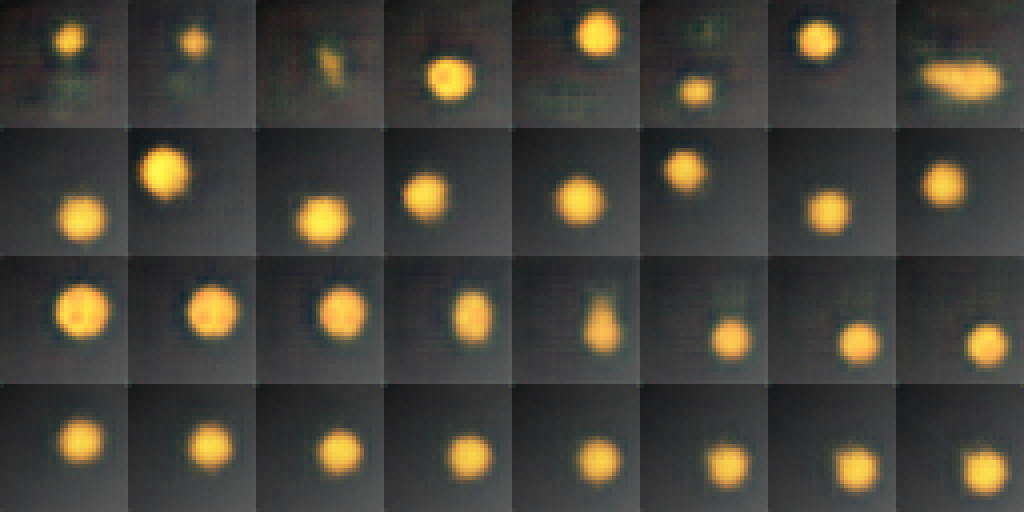

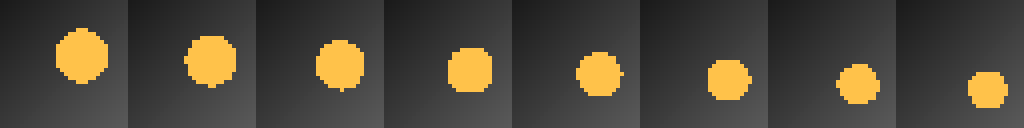

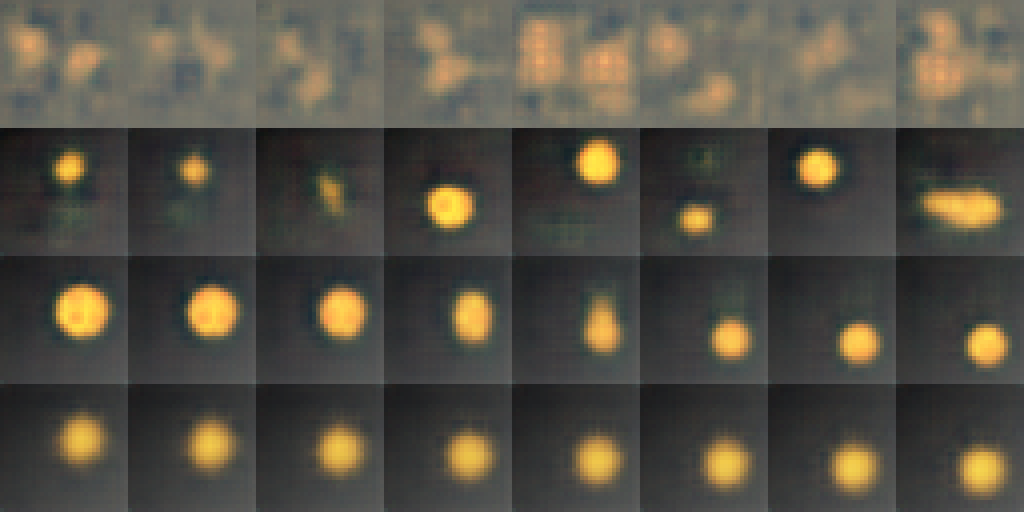

In [0]:
display(load(joinpath(ROOT8,"artifacts","comparison.png")))
display(load(joinpath(ROOT8,"artifacts","interpolation_true_path.png")))
display(load(joinpath(ROOT8,"artifacts","comparison_demo_variant01.png")))

## Вывод по фактическим данным

# Итоговый вывод

Ожидание падения реконструкции более 1 дБ подтвердилось, ожидание падения среднего R² более 0,05 подтвердилось в данной серии. Менялось только d: 8→2; β, обучение, данные, seed и методы оценки сохранены.

recon: A=26.37189, B=23.22424, Δ=-3.14766; |Δ|/s_A=5.127. Класс по допуску 1.00: «ухудшение». Критерий 2s выполнен; согласуется с признаком превышения практического допуска.

interp: A=22.55258, B=22.97955, Δ=+0.42697; |Δ|/s_A=0.881. Класс по допуску 1.00: «нейтрально». Критерий 2s не выполнен; согласуется с признаком превышения практического допуска.

sample: A=23.24185, B=24.46666, Δ=+1.22481; |Δ|/s_A=2.204. Класс по допуску 1.00: «улучшение». Критерий 2s выполнен; согласуется с признаком превышения практического допуска.

r2: A=0.89948, B=0.64782, Δ=-0.25167; |Δ|/s_A=11.464. Класс по допуску 0.05: «ухудшение». Критерий 2s выполнен; согласуется с признаком превышения практического допуска.

Узкое место изменяет компромисс между точностью конкретной сцены и свойствами латентного пространства. Не требуется, чтобы все четыре метрики ухудшались одновременно. Среднее по seed показывает картину этой серии, а не универсальное свойство любого VAE.

Диагностика AE/VAE seed101: сэмплы AE β=0 имеют PSNR 12.8617, VAE β=1 — 23.2810. Это показывает практический смысл согласования с prior в этих условиях. Метрика ближайшего соседа не измеряет разнообразия и не исключает повторяющиеся сэмплы.

Для объяснения потерь используются R² каждого фактора и визуальный путь, но три порождающих фактора сами по себе не доказывают строгую минимальную размерность дискретных изображений. Линейная регрессия не равна полной оценке информации. Пять seed, один синтетический набор и одна архитектура не позволяют переносить результат на фотографии. Критерий 2s не является формальным тестом. CPU-обучение и время не обещают побитовой воспроизводимости; новый сеанс отдельно не проверен.


# Визуальная оценка

В сэмплах A (первая строка) радиус и яркость сильно различаются: есть слабые маленькие пятна, а у последнего примера видны несколько слившихся ярких областей. В B (вторая строка) получились более одинаковые округлые диски с разными положениями, но меньшей видимой вариативностью радиуса. Это согласуется с улучшением метрики ближайшего соседа без гарантии разнообразия.

На интерполяционных рядах A/B диск постепенно смещается преимущественно вниз и немного вправо. Явной пары раздельных дисков в выбранном пути не видно, но границы размыты. В A радиус меняется, отдельные промежуточные пятна вытянуты; в B форма более однотипна и радиус почти постоянен, тогда как истинный путь показывает его уменьшение. Поэтому требование о плавном восстановлении положения и радиуса выполнено частично.

Осмотр относится к одной паре test-сцен 0 и2 и seed101. Визуальный лист имеет 8 t с шагом 1/7; численная метрика интерполяции рассчитана отдельно на 200 парах и t=0,25/0,5/0,75. По одному листу нельзя оценивать всё распределение сэмплов или доказывать полную потерю фактора.


# Анализ диагностики

Режим A: активные оси по seed101–105: 7/8, 5/8, 8/8, 6/8, 7/8.

Режим B: активные оси по seed101–105: 2/2, 2/2, 2/2, 2/2, 2/2.

По факторам сцены (средние R² по пяти seed): r2_x: A=0.88508, B=0.97044, Δ=+0.08536; r2_y: A=0.86937, B=0.97627, Δ=+0.10690; r2_radius: A=0.94401, B=-0.00325, Δ=-0.94726.

Наибольшее падение линейной восстанавливаемости имеет радиус. Это согласуется с ожиданием о потере информации о радиусе.

R² измеряет линейное восстановление факторов, а не всю доступную информацию. Низкий R² радиуса не доказывает его полного отсутствия в нелинейном коде. Активные оси не обязательно совпадают с независимыми семантическими факторами; две оси могут смешивать положение и радиус.


# Анализ схлопывания

Без разогрева худший seed 102 дал реконструкцию 17.1571 дБ; с warmup10 тот же seed дал 26.8770 дБ. Для ориентира средняя train-картинка, заново оценённая по данным ЛР8 на test, даёт 17.1707 дБ. В этой диагностике провал без warmup близок к тривиальному ответу, а разогрев его устранил в проверенной паре.

Это наблюдение согласуется с описанным в методичке схлопыванием. Сам по себе низкий PSNR не является исчерпывающим доказательством posterior collapse: для дополнительной серии сохранены метрики, но полные распределения каждого такого запуска отдельно не исследуются. Гарантии, что warmup исключает все будущие провалы, не даются. Новая сессия отдельно не проверялась.


# Ответы на контрольные вопросы

1. Кодировщик VAE выдаёт μ и log σ² диагонального нормального распределения. Репараметризация z=μ+σ·ε, ε~N(0,I), отделяет случайность от обучаемых μ/σ и позволяет передавать градиент через выборку.

2. Потери - сумма квадратов реконструкции по пикселям и β·KL(q(z|x)||N(0,I)). Первое слагаемое сохраняет изображение; KL ограничивает передачу информации и согласует распределения с prior. Важна нормировка: замена суммы на среднее без изменения β меняет относительную силу регуляризации.

3. У обычного AE нет требования, чтобы его коды соответствовали N(0,I). Случайные нормальные точки могут оказаться вне области кодов, поэтому такая генерация без проверки необоснованна. Это не абсолютный запрет: требуется диагностика распределения и качества. В работе сравниваются реальные сэмплы AE и VAE.

4. Больший β усиливает регуляризацию и может ухудшить реконструкцию и отключить часть осей. Улучшение интерполяции и сэмплов не гарантируется; чрезмерная регуляризация может схлопнуть представление. Вывод делается по фактическому демо, а не только по интуиции о гладкости.

5. Смешивание пикселей даёт наложение исходных изображений и часто два полупрозрачных объекта. Интерполяция кодов с последующим декодированием может перемещать один объект и менять его свойства нелинейно. Это проверяется по истинному пути факторов и наличию двойных контуров.

6. Линейная интерполяция идёт по отрезку; сферическая использует угол между векторами и синусные веса, лучше сохраняет типичную норму при сопоставимых исходных длинах. Различия заметны для достаточно разных направлений; при почти коллинеарных кодах библиотека использует линейный путь. Slerp не гарантирует большего PSNR.

7. KL=−0,5·(1+log1−0,5²−1)=0,125 нат для одной оси.

8. При смене только способа интерполяции используются те же обученные веса и кодирование; реконструкция, сэмплы и R² не зависят от пути. Их неизменность - контроль. В нашем варианте3 меняется d, поэтому все четыре метрики могут изменяться.

9. По принятому критерию активна ось со средним KL>0,05 нат на test. Дополнительно смотрят std μ. Малый разброс μ и малый KL согласуются с неиспользуемой осью; один разброс не заменяет проверку распределения. Активность оси не доказывает её соответствия одному конкретному фактору.

10. Нужны исходные файлы и SHA-256, набор и seed данных, train/test и факторы, архитектура и d, β и warmup, seed обучения, эпохи/оптимизатор/lr/batch, dtype, CPU и число потоков, Python/PyTorch/NumPy/Engee, seed пар и сэмплов, t и температура, методы метрик и допуски. Побитовое совпадение и одинаковое время на другой машине не обещаются.


Источники: приложенные методические указания ЛР8 и исходники; [Kingma и Welling](https://arxiv.org/abs/1312.6114), [документация PyTorch](https://docs.pytorch.org/docs/stable/nn.html). Анализ добавлен после фактического выполнения в Engee. Код и выводы вычислительных ячеек сохранены без изменения; метрики независимо пересчитаны. Снимок консоли приложен в reports/console_summary.png.